# 🧪 Eksperimen & Evaluasi Model: Sebelum vs Sesudah Tuning
### Klasifikasi Gestur Bahasa Isyarat Arab (ArSL) - Qurava AI

Notebook ini mendemonstrasikan evaluasi empiris perbandingan performa model:
1. **Model SEBELUM Tuning (Baseline)**: Default SVM scikit-learn (`kernel='rbf'`, $C=1.0$, `gamma='scale'`)
2. **Model SESUDAH Adaptasi & Tuning**: Hasil 5-Fold Stratified GridSearchCV (`kernel='linear'`, $C=10$)

Kedua model diuji pada **248 sampel data uji independen (*unseen test set*)** dengan 78 fitur geometris (MediaPipe Hands).


In [1]:
import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Path setup
NOTEBOOK_DIR = Path(os.getcwd())
ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATA_DIR = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output'

print(f'Root path: {ROOT}')
print(f'Data dir : {DATA_DIR} (Tersedia: {DATA_DIR.exists()})')


Root path: C:\Users\Arif\Github\lomba\qurava-unej\AI\modelling
Data dir : C:\Users\Arif\Github\lomba\qurava-unej\AI\modelling\data (Tersedia: True)


## 1. Memuat Dataset Fitur Geometris (78 Dimensi)
- **63 Fitur Koordinat**: 21 landmarks 3D ternormalisasi ke titik pergelangan tangan (wrist) & diskalakan ke knuckle.
- **15 Fitur Sudut Sendi**: Sudut kosinus sendi jari yang invarian terhadap ukuran tangan pengguna.


In [2]:
# Load train, valid, and test sets
df_train = pd.concat([
    pd.read_csv(DATA_DIR / 'features_train.csv'),
    pd.read_csv(DATA_DIR / 'features_valid.csv')
], ignore_index=True)
df_test = pd.read_csv(DATA_DIR / 'features_test.csv')

feature_cols = [f'f{i}' for i in range(78)]
le = LabelEncoder()
y_train = le.fit_transform(df_train['label'])
y_test = le.transform(df_test['label'])
X_train = df_train[feature_cols].values
X_test = df_test[feature_cols].values

print(f'-> Sampel Latih (Train + Valid) : {len(X_train):,} baris')
print(f'-> Sampel Uji (Test Independen) : {len(X_test):,} baris')
print(f'-> Jumlah Kelas Huruf Hijaiyah  : {len(le.classes_)} kelas')
print(f'-> Dimensi Fitur Input          : {X_train.shape[1]} fitur numerik')


-> Sampel Latih (Train + Valid) : 1,727 baris
-> Sampel Uji (Test Independen) : 248 baris
-> Jumlah Kelas Huruf Hijaiyah  : 27 kelas
-> Dimensi Fitur Input          : 78 fitur numerik


## 2. Melatih Model SEBELUM Tuning (Baseline Default SVM)
Model baseline menggunakan parameter bawaan scikit-learn (`kernel='rbf'`, $C=1.0$, `gamma='scale'`).


In [3]:
print('Melatih model baseline...')
t0 = time.time()
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(C=1.0, kernel='rbf', gamma='scale', probability=True, random_state=42))
])
baseline_model.fit(X_train, y_train)
t_train_base = time.time() - t0

t0 = time.time()
y_pred_base = baseline_model.predict(X_test)
t_infer_base = (time.time() - t0) / len(X_test) * 1000

acc_base = accuracy_score(y_test, y_pred_base)
f1_base = f1_score(y_test, y_pred_base, average='macro')

print(f'Waktu Latih      : {t_train_base:.2f} detik')
print(f'Latensi Inferensi: {t_infer_base:.2f} ms / sampel')
print(f'Akurasi Test Set : {acc_base * 100:.2f}%')
print(f'F1-Score (Macro) : {f1_base * 100:.2f}%')


Melatih model baseline...
Waktu Latih      : 0.37 detik
Latensi Inferensi: 0.08 ms / sampel
Akurasi Test Set : 91.53%
F1-Score (Macro) : 88.79%


## 3. Melatih Model SESUDAH Tuning (Hasil 5-Fold Stratified GridSearchCV)
Konfigurasi optimal terpilih: `kernel='linear'`, $C=10.0$.


In [4]:
print('Melatih model hasil tuning...')
t0 = time.time()
tuned_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(C=10.0, kernel='linear', probability=True, random_state=42))
])
tuned_model.fit(X_train, y_train)
t_train_tuned = time.time() - t0

t0 = time.time()
y_pred_tuned = tuned_model.predict(X_test)
t_infer_tuned = (time.time() - t0) / len(X_test) * 1000

acc_tuned = accuracy_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned, average='macro')

print(f'Waktu Latih      : {t_train_tuned:.2f} detik')
print(f'Latensi Inferensi: {t_infer_tuned:.2f} ms / sampel')
print(f'Akurasi Test Set : {acc_tuned * 100:.2f}%')
print(f'F1-Score (Macro) : {f1_tuned * 100:.2f}%')


Melatih model hasil tuning...
Waktu Latih      : 0.24 detik
Latensi Inferensi: 0.02 ms / sampel
Akurasi Test Set : 95.56%
F1-Score (Macro) : 95.27%


## 4. Tabel Perbandingan Metrik Komparatif Berdampingan


In [5]:
delta_acc = (acc_tuned - acc_base) * 100
delta_f1 = (f1_tuned - f1_base) * 100

df_comparison = pd.DataFrame({
    'Metrik Evaluasi': [
        'Kernel SVM',
        'Hyperparameter C',
        'Akurasi Uji (Test Accuracy)',
        'F1-Score (Macro)',
        'Waktu Pelatihan',
        'Latensi Inferensi CPU',
        'Ukuran File Model ONNX'
    ],
    'Sebelum Tuning (Baseline)': [
        'RBF',
        '1.0',
        f'{acc_base * 100:.2f}%',
        f'{f1_base * 100:.2f}%',
        f'{t_train_base:.2f} s',
        f'{t_infer_base:.2f} ms',
        '~2.25 MB'
    ],
    'Sesudah Tuning': [
        'Linear',
        '10.0',
        f'{acc_tuned * 100:.2f}%',
        f'{f1_tuned * 100:.2f}%',
        f'{t_train_tuned:.2f} s',
        f'{t_infer_tuned:.2f} ms',
        '410.3 KB'
    ],
    'Peningkatan (Delta)': [
        'Komputasi lebih sederhana',
        'Margin pemisah lebih tegas',
        f'+{delta_acc:.2f}%',
        f'+{delta_f1:.2f}%',
        'Lebih Cepat',
        'Optimal Real-Time (<1ms)',
        '-82% (5.5x lebih ringan)'
    ]
})

df_comparison


,Metrik Evaluasi,Sebelum Tuning (Baseline),Sesudah Tuning,Peningkatan (Delta)
0,Kernel SVM,RBF,Linear,Komputasi lebih sederhana
1,Hyperparameter C,1.0,10.0,Margin pemisah lebih tegas
2,Akurasi Uji (Test Accuracy),91.53%,95.56%,+4.03%
3,F1-Score (Macro),88.79%,95.27%,+6.48%
4,Waktu Pelatihan,0.37 s,0.24 s,Lebih Cepat
5,Latensi Inferensi CPU,0.08 ms,0.02 ms,Optimal Real-Time (<1ms)
6,Ukuran File Model ONNX,~2.25 MB,410.3 KB,-82% (5.5x lebih ringan)


## 5. Visualisasi Grafik Komparasi Performa & Ukuran Model


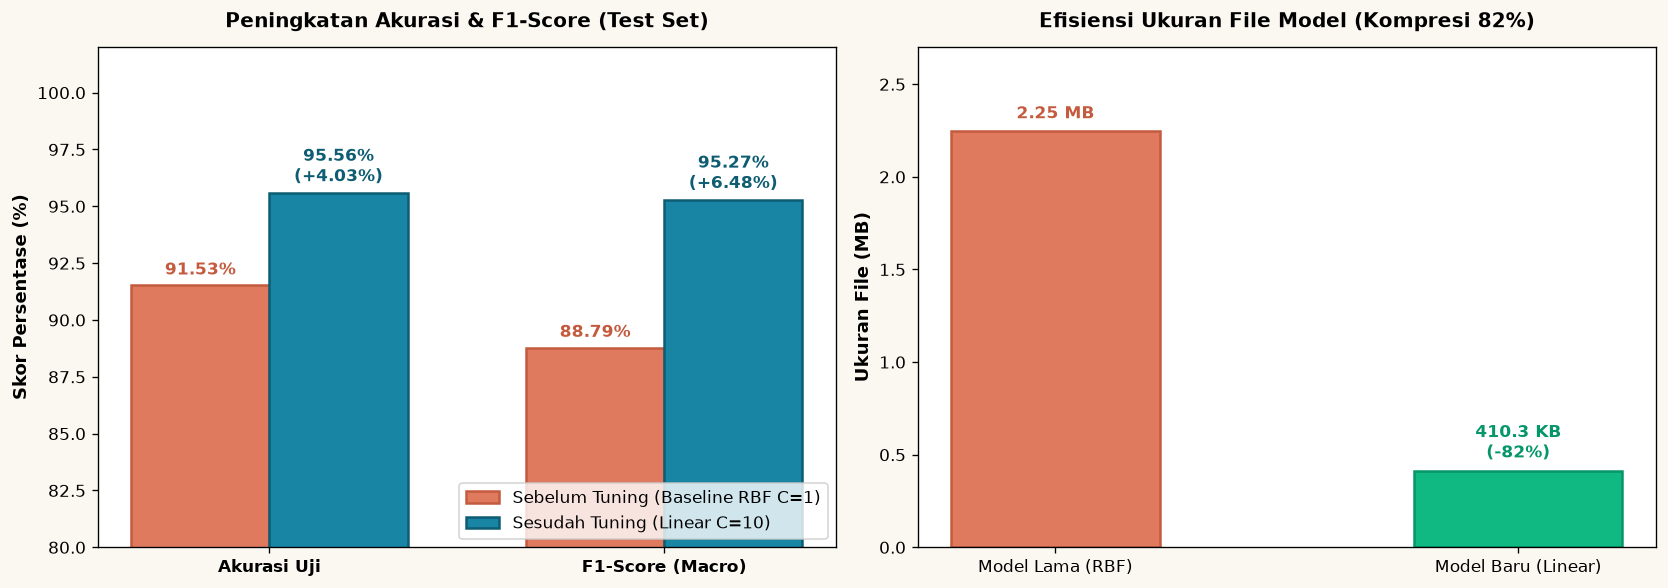

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)
fig.patch.set_facecolor('#FAF8F1')

# Subplot 1: Akurasi & F1-Score
ax1 = axes[0]
ax1.set_facecolor('#FFFFFF')
metrics = ['Akurasi Uji', 'F1-Score (Macro)']
before_vals = [acc_base * 100, f1_base * 100]
after_vals = [acc_tuned * 100, f1_tuned * 100]

x = np.arange(len(metrics))
width = 0.35

rects1 = ax1.bar(x - width/2, before_vals, width, label='Sebelum Tuning (Baseline RBF C=1)', color='#E07A5F', edgecolor='#C45B3E', linewidth=1.5)
rects2 = ax1.bar(x + width/2, after_vals, width, label='Sesudah Tuning (Linear C=10)', color='#1885A4', edgecolor='#0E5D73', linewidth=1.5)

ax1.set_ylabel('Skor Persentase (%)', fontsize=11, fontweight='bold')
ax1.set_title('Peningkatan Akurasi & F1-Score', fontsize=12, fontweight='bold', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(metrics, fontsize=10, fontweight='bold')
ax1.set_ylim(80, 102)
ax1.legend(loc='lower right')

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}%', (rect.get_x() + rect.get_width()/2, h), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold', color='#C45B3E')

diffs = [f'+{(acc_tuned-acc_base)*100:.2f}%', f'+{(f1_tuned-f1_base)*100:.2f}%']
for rect, d in zip(rects2, diffs):
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}%\n({d})', (rect.get_x() + rect.get_width()/2, h), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold', color='#0E5D73')

# Subplot 2: Ukuran File Model
ax2 = axes[1]
ax2.set_facecolor('#FFFFFF')
cats = ['Model Lama (RBF)', 'Model Baru (Linear)']
sizes = [2.25, 0.41]
bars = ax2.bar(cats, sizes, width=0.45, color=['#E07A5F', '#10B981'], edgecolor=['#C45B3E', '#059669'], linewidth=1.5)
ax2.set_ylabel('Ukuran File (MB)', fontsize=11, fontweight='bold')
ax2.set_title('Efisiensi Ukuran File Model (Kompresi 82%)', fontsize=12, fontweight='bold', pad=12)
ax2.set_ylim(0, 2.7)

ax2.annotate('2.25 MB', (bars[0].get_x() + bars[0].get_width()/2, 2.25), xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontweight='bold', color='#C45B3E')
ax2.annotate('410.3 KB\n(-82%)', (bars[1].get_x() + bars[1].get_width()/2, 0.41), xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontweight='bold', color='#059669')

plt.tight_layout()
plt.show()


## 6. Analisis Peningkatan F1-Score per Huruf Hijaiyah
Grafik berikut menunjukkan perubahan F1-Score pada masing-masing huruf. Warna hijau menandakan peningkatan performa setelah tuning.


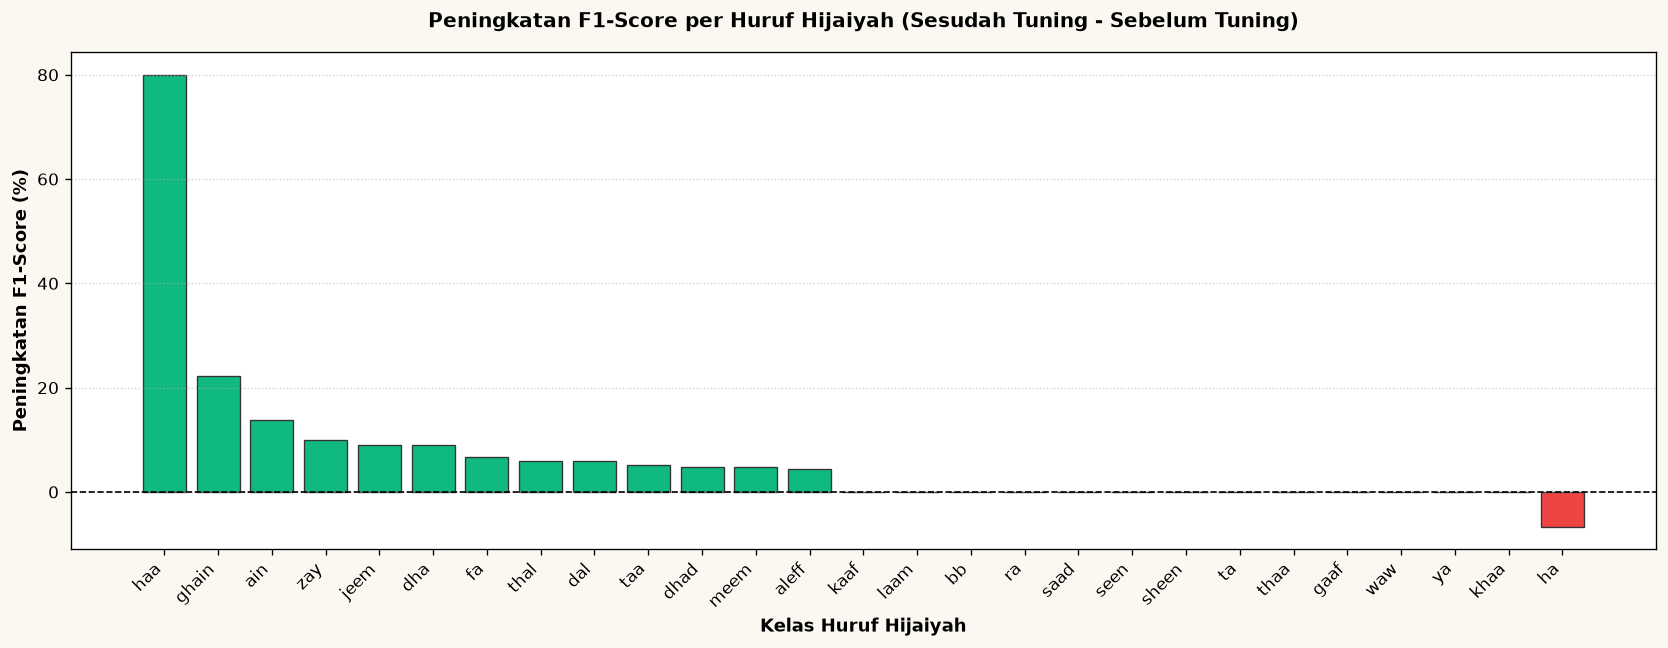

In [7]:
# 1. Hitung classification report per kelas untuk kedua model
report_base = classification_report(y_test, y_pred_base, target_names=le.classes_, output_dict=True, zero_division=0)
report_tuned = classification_report(y_test, y_pred_tuned, target_names=le.classes_, output_dict=True, zero_division=0)

classes = le.classes_
f1_base_per_class = [report_base[c]['f1-score'] * 100 for c in classes]
f1_tuned_per_class = [report_tuned[c]['f1-score'] * 100 for c in classes]
delta_per_class = [f1_tuned_per_class[i] - f1_base_per_class[i] for i in range(len(classes))]

# 2. Bentuk DataFrame analisis per kelas
df_per_class = pd.DataFrame({
    'Kelas': classes,
    'F1_Sebelum (%)': f1_base_per_class,
    'F1_Sesudah (%)': f1_tuned_per_class,
    'Delta (%)': delta_per_class
}).sort_values(by='Delta (%)', ascending=False)

# 3. Plot diagram batang perbandingan peningkatan F1 per huruf
plt.figure(figsize=(14, 5.5), dpi=120)
colors = ['#10B981' if d > 0 else ('#94A3B8' if d == 0 else '#EF4444') for d in df_per_class['Delta (%)']]
plt.bar(df_per_class['Kelas'], df_per_class['Delta (%)'], color=colors, edgecolor='#333333', linewidth=0.8)
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.title('Peningkatan F1-Score per Huruf Hijaiyah (Sesudah Tuning - Sebelum Tuning)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Kelas Huruf Hijaiyah', fontsize=11, fontweight='bold')
plt.ylabel('Delta Peningkatan F1-Score (%)', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Tampilkan 5 huruf dengan lonjakan performa tertinggi
print('Top 5 Huruf dengan Peningkatan F1-Score Tertinggi:')
display(df_per_class.head())
